# Regresion logistica multinomial: segmentacion de clientes y analisis de clasificacion

Se utiliza `Ventas_CLV_2022_2026.csv` para construir cinco objetivos categoricos por cliente: CLV, frecuencia de compra, ticket promedio, diversidad de productos y volumen de unidades. Cada objetivo se evalua en un experimento separado con una particion estratificada de entrenamiento y prueba.

El preprocesamiento revisa nulos y valores extremos; las variables numericas se imputan, transforman con `log1p` y estandarizan, mientras las categoricas se imputan y codifican con one-hot. Los extremos comerciales se conservan (pueden ser clientes reales de alto valor) y se reduce su asimetria con la transformacion logaritmica. Se excluyen del modelo las variables que definen directamente cada objetivo para evitar fuga de informacion.

Las metricas describen clasificacion predictiva, no causalidad. Aunque el nombre del archivo indica 2022-2026, las fechas disponibles deben verificarse: el conjunto podria no contener registros de todos esos anos.

In [1]:
# Librerias para preprocesamiento, regresion multinomial y evaluacion
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

In [2]:
# Cargamos el archivo de ventas
# El CSV debe estar en la misma carpeta que este notebook.
df = pd.read_csv("Ventas_CLV_2022_2026.csv")
print(f"Registros: {len(df):,}; columnas: {df.shape[1]}")
df.head()

Registros: 114,501; columnas: 15


,fecha_documento,folio_abreviado,folio,articulo_id,clave_articulo,nombre_articulo,marca,precio_unitario,total_unidades,total_neto,nombre_cliente,estado,ciudad,cp,vendedor
0,11.09.2026,B00,B00013017,7688,MFTL374M2,MFT L37 4M2,VITA,172.413793,1,172.41,HUGO CARRILLO SANPEDRO SF,Ciudad de México,CDMX,6100.0,JAVIERCAD
1,11.09.2026,B00,B00013017,7895,MFTPL313R2.5,MFT PL31 3R2.5,VITA,172.413793,1,172.41,HUGO CARRILLO SANPEDRO SF,Ciudad de México,CDMX,6100.0,JAVIERCAD
2,11.09.2026,B00,B00013017,7985,MFTPU313R2.5,MFT PU31 3R2.5,VITA,172.413793,2,344.83,HUGO CARRILLO SANPEDRO SF,Ciudad de México,CDMX,6100.0,JAVIERCAD
3,11.09.2026,B00,B00013017,8258,MFTT464M2,MFT T46 4M2,VITA,172.413793,2,344.83,HUGO CARRILLO SANPEDRO SF,Ciudad de México,CDMX,6100.0,JAVIERCAD
4,11.09.2026,A00,A00018080,7613,MFTL332M2,MFT L33 2M2,VITA,156.740000,1,156.74,JUAN PEDRO OLVERA ALONSO,Querétaro,Querétaro,76079.0,SERGIO SANCHEZ


In [3]:
# Revisamos valores faltantes y convertimos la fecha
nulos = df.isna().sum().sort_values(ascending=False)
print("Valores nulos por columna:")
display(nulos.rename("Nulos").to_frame())

df["fecha_documento"] = pd.to_datetime(
    df["fecha_documento"], dayfirst=True, errors="coerce"
)
print("Fechas no convertibles:", int(df["fecha_documento"].isna().sum()))
print("Periodo observado:", df["fecha_documento"].min(), "a", df["fecha_documento"].max())
anios_observados = set(df["fecha_documento"].dt.year.dropna().astype(int))
anios_sin_registros = sorted(set(range(2022, 2027)) - anios_observados)
print("Anios 2022-2026 sin registros:", anios_sin_registros)

df = df.drop(columns=["cp"])

Valores nulos por columna:


,Nulos
cp,5188
folio_abreviado,0
fecha_documento,0
articulo_id,0
clave_articulo,0
nombre_articulo,0
folio,0
marca,0
precio_unitario,0
total_neto,0


Fechas no convertibles: 0
Periodo observado: 2023-01-02 00:00:00 a 2026-09-11 00:00:00
Anios 2022-2026 sin registros: [2022]


In [4]:
# Agregamos las transacciones a nivel cliente
def obtener_moda(serie):
    modas = serie.mode()
    return modas.iloc[0] if not modas.empty else "Sin dato"

clientes = df.groupby("nombre_cliente").agg(
    ventas_totales=("total_neto", "sum"),
    facturas=("folio", "nunique"),
    unidades_totales=("total_unidades", "sum"),
    productos_distintos=("clave_articulo", "nunique"),
    marcas_distintas=("marca", "nunique"),
    precio_promedio=("precio_unitario", "mean"),
    estado=("estado", obtener_moda),
    ciudad=("ciudad", obtener_moda),
    vendedor=("vendedor", obtener_moda),
)
clientes["ticket_promedio"] = clientes["ventas_totales"] / clientes["facturas"].clip(lower=1)

# Creamos cinco objetivos categoricos de tres clases.
etiquetas_terciles = ["Bajo", "Medio", "Alto"]
clientes["CLV"] = pd.qcut(clientes["ventas_totales"], q=3, labels=etiquetas_terciles)
clientes["Frecuencia"] = pd.cut(
    clientes["facturas"],
    bins=[0, 1, 3, np.inf],
    labels=["Unica", "Ocasional", "Recurrente"],
    include_lowest=True,
)
clientes["Ticket"] = pd.qcut(clientes["ticket_promedio"], q=3, labels=etiquetas_terciles)
clientes["Diversidad"] = pd.qcut(clientes["productos_distintos"], q=3, labels=etiquetas_terciles)
clientes["Volumen"] = pd.qcut(clientes["unidades_totales"], q=3, labels=etiquetas_terciles)
print(f"Clientes analizados: {len(clientes):,}")
clientes.head()

Clientes analizados: 4,743


,ventas_totales,facturas,unidades_totales,productos_distintos,marcas_distintas,precio_promedio,estado,ciudad,vendedor,ticket_promedio,CLV,Frecuencia,Ticket,Diversidad,Volumen
nombre_cliente,,,,,,,,,,,,,,,
MARTHA CUELLAR PIÑA,8534.48,1,3,3,1,2844.827333,Querétaro,Corregidora,RENE,8534.480,Medio,Unica,Medio,Bajo,Bajo
3D DIGITAL DENTAL DESIGN,84579.24,12,69,26,4,1196.356104,Coahuila,Torreón,CLAUDIA,7048.270,Alto,Recurrente,Medio,Alto,Alto
3D FACTORY MEXICO,55356.90,2,9,9,1,6150.766667,Nuevo León,Monterrey,GERARDO / BO ENRIQUE,27678.450,Alto,Ocasional,Alto,Alto,Medio
A W A INFRAESTRUCTURA,724.12,1,4,4,1,181.034400,Michoacán,Michoacan,EFREN,724.120,Bajo,Unica,Bajo,Medio,Medio
AARON RICARDO DEL ANGEL ZAMACONA SF,1810.33,2,5,5,2,362.066000,Tamaulipas,Tampico,GERARDO,905.165,Bajo,Ocasional,Bajo,Medio,Medio


In [5]:
# Detectamos valores extremos mediante la regla de 1.5 veces el rango intercuartilico
# No se eliminan ni limitan: los grandes clientes pueden ser observaciones validas.
variables_a_revisar = [
    "ventas_totales", "facturas", "unidades_totales",
    "productos_distintos", "marcas_distintas", "precio_promedio", "ticket_promedio",
]
reporte_outliers = []
for variable in variables_a_revisar:
    valores = clientes[variable].dropna()
    q1, q3 = valores.quantile([0.25, 0.75])
    iqr = q3 - q1
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr
    extremos = ((valores < limite_inferior) | (valores > limite_superior)).sum()
    reporte_outliers.append({
        "Variable": variable,
        "Limite inferior IQR": limite_inferior,
        "Limite superior IQR": limite_superior,
        "Valores extremos": int(extremos),
    })
display(pd.DataFrame(reporte_outliers).set_index("Variable"))

objetivos = ["CLV", "Frecuencia", "Ticket", "Diversidad", "Volumen"]
for objetivo in objetivos:
    print(f"\nDistribucion de {objetivo}:")
    display(clientes[objetivo].value_counts().rename_axis(objetivo).to_frame("Clientes"))

,Limite inferior IQR,Limite superior IQR,Valores extremos
Variable,,,
ventas_totales,-120667.220000,207525.820000,467
facturas,-3.500000,8.500000,686
unidades_totales,-22.000000,42.000000,669
productos_distintos,-11.500000,24.500000,565
marcas_distintas,-0.500000,3.500000,626
precio_promedio,-9227.136091,16556.971278,843
ticket_promedio,-31249.998750,55370.691250,765



Distribucion de CLV:


,Clientes
CLV,
Bajo,1581
Medio,1581
Alto,1581



Distribucion de Frecuencia:


,Clientes
Frecuencia,
Unica,2212
Recurrente,1377
Ocasional,1154



Distribucion de Ticket:


,Clientes
Ticket,
Bajo,1581
Medio,1581
Alto,1581



Distribucion de Diversidad:


,Clientes
Diversidad,
Bajo,1954
Alto,1458
Medio,1331



Distribucion de Volumen:


,Clientes
Volumen,
Bajo,1710
Alto,1545
Medio,1488


In [6]:
# Definimos los predictores excluyendo las variables que definen cada objetivo
variables_categoricas = ["estado", "ciudad", "vendedor"]
experimentos = {
    "CLV por ventas netas": {
        "objetivo": "CLV",
        "numericas": ["facturas", "unidades_totales", "productos_distintos", "marcas_distintas"],
    },
    "Frecuencia de compra": {
        "objetivo": "Frecuencia",
        "numericas": ["unidades_totales", "productos_distintos", "marcas_distintas"],
    },
    "Ticket promedio": {
        "objetivo": "Ticket",
        "numericas": ["facturas", "unidades_totales", "productos_distintos", "marcas_distintas"],
    },
    "Diversidad de productos": {
        "objetivo": "Diversidad",
        "numericas": ["facturas", "unidades_totales", "marcas_distintas"],
    },
    "Volumen de unidades": {
        "objetivo": "Volumen",
        "numericas": ["facturas", "productos_distintos", "marcas_distintas"],
    },
}

preparador_numerico = Pipeline(steps=[
    ("imputacion", SimpleImputer(strategy="median")),
    ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ("estandarizacion", StandardScaler()),
])
preparador_categorico = Pipeline(steps=[
    ("imputacion", SimpleImputer(strategy="most_frequent")),
    ("codificacion", OneHotEncoder(handle_unknown="ignore")),
])

In [7]:
# Entrenamos y evaluamos un modelo multinomial independiente para cada objetivo
resultados = {}
for nombre, especificacion in experimentos.items():
    objetivo = especificacion["objetivo"]
    variables_numericas = especificacion["numericas"]
    predictores = variables_numericas + variables_categoricas
    X = clientes[predictores]
    y = clientes[objetivo].astype(str)
    etiquetas = clientes[objetivo].cat.categories.astype(str).tolist()

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.30, random_state=42, stratify=y
    )
    preprocesamiento = ColumnTransformer(transformers=[
        ("numericas", preparador_numerico, variables_numericas),
        ("categoricas", preparador_categorico, variables_categoricas),
    ])
    modelo = Pipeline(steps=[
        ("preprocesamiento", preprocesamiento),
        ("clasificador", LogisticRegression(solver="lbfgs", max_iter=2000)),
    ])
    modelo.fit(X_train, y_train)
    predicciones = modelo.predict(X_test)
    matriz = confusion_matrix(y_test, predicciones, labels=etiquetas)

    resultados[nombre] = {
        "objetivo": objetivo,
        "etiquetas": etiquetas,
        "matriz": matriz,
        "precision_macro": precision_score(y_test, predicciones, average="macro", zero_division=0),
        "exactitud": accuracy_score(y_test, predicciones),
        "sensibilidad_macro": recall_score(y_test, predicciones, average="macro", zero_division=0),
        "reporte": classification_report(
            y_test, predicciones, labels=etiquetas, zero_division=0, output_dict=True
        ),
    }

    print(f"\n=== {nombre} ===")
    print("Predictores numericos:", variables_numericas)
    print("Predictores categoricos:", variables_categoricas)
    print("Precision macro:", round(resultados[nombre]["precision_macro"], 4))
    print("Exactitud:", round(resultados[nombre]["exactitud"], 4))
    print("Sensibilidad (recall macro):", round(resultados[nombre]["sensibilidad_macro"], 4))
    print("Matriz de confusion (filas=real; columnas=prediccion; orden:", etiquetas, ")")
    display(pd.DataFrame(matriz, index=etiquetas, columns=etiquetas))


=== CLV por ventas netas ===
Predictores numericos: ['facturas', 'unidades_totales', 'productos_distintos', 'marcas_distintas']
Predictores categoricos: ['estado', 'ciudad', 'vendedor']
Precision macro: 0.6186
Exactitud: 0.6226
Sensibilidad (recall macro): 0.6227
Matriz de confusion (filas=real; columnas=prediccion; orden: ['Bajo', 'Medio', 'Alto'] )


,Bajo,Medio,Alto
Bajo,355,91,28
Medio,112,231,132
Alto,74,100,300



=== Frecuencia de compra ===
Predictores numericos: ['unidades_totales', 'productos_distintos', 'marcas_distintas']
Predictores categoricos: ['estado', 'ciudad', 'vendedor']
Precision macro: 0.7005
Exactitud: 0.7358
Sensibilidad (recall macro): 0.6879
Matriz de confusion (filas=real; columnas=prediccion; orden: ['Unica', 'Ocasional', 'Recurrente'] )


,Unica,Ocasional,Recurrente
Unica,581,51,32
Ocasional,159,129,58
Recurrente,21,55,337



=== Ticket promedio ===
Predictores numericos: ['facturas', 'unidades_totales', 'productos_distintos', 'marcas_distintas']
Predictores categoricos: ['estado', 'ciudad', 'vendedor']
Precision macro: 0.5611
Exactitud: 0.5657
Sensibilidad (recall macro): 0.5658
Matriz de confusion (filas=real; columnas=prediccion; orden: ['Bajo', 'Medio', 'Alto'] )


,Bajo,Medio,Alto
Bajo,341,83,50
Medio,129,203,143
Alto,105,108,261



=== Diversidad de productos ===
Predictores numericos: ['facturas', 'unidades_totales', 'marcas_distintas']
Predictores categoricos: ['estado', 'ciudad', 'vendedor']
Precision macro: 0.8414
Exactitud: 0.8503
Sensibilidad (recall macro): 0.8412
Matriz de confusion (filas=real; columnas=prediccion; orden: ['Bajo', 'Medio', 'Alto'] )


,Bajo,Medio,Alto
Bajo,529,51,6
Medio,58,296,45
Alto,0,53,385



=== Volumen de unidades ===
Predictores numericos: ['facturas', 'productos_distintos', 'marcas_distintas']
Predictores categoricos: ['estado', 'ciudad', 'vendedor']
Precision macro: 0.8799
Exactitud: 0.8805
Sensibilidad (recall macro): 0.8793
Matriz de confusion (filas=real; columnas=prediccion; orden: ['Bajo', 'Medio', 'Alto'] )


,Bajo,Medio,Alto
Bajo,462,51,0
Medio,26,376,44
Alto,4,45,415


In [8]:
# Comparamos las metricas solicitadas y mostramos el reporte por clase
resumen = pd.DataFrame([
    {
        "Analisis": nombre,
        "Precision macro": resultado["precision_macro"],
        "Exactitud": resultado["exactitud"],
        "Sensibilidad macro": resultado["sensibilidad_macro"],
    }
    for nombre, resultado in resultados.items()
]).set_index("Analisis")
display(resumen.round(4))

for nombre, resultado in resultados.items():
    print(f"\nReporte por clase: {nombre}")
    display(pd.DataFrame(resultado["reporte"]).T.round(3))

,Precision macro,Exactitud,Sensibilidad macro
Analisis,,,
CLV por ventas netas,0.6186,0.6226,0.6227
Frecuencia de compra,0.7005,0.7358,0.6879
Ticket promedio,0.5611,0.5657,0.5658
Diversidad de productos,0.8414,0.8503,0.8412
Volumen de unidades,0.8799,0.8805,0.8793



Reporte por clase: CLV por ventas netas


,precision,recall,f1-score,support
Bajo,0.656,0.749,0.700,474.000
Medio,0.547,0.486,0.515,475.000
Alto,0.652,0.633,0.642,474.000
accuracy,0.623,0.623,0.623,0.623
macro avg,0.619,0.623,0.619,1423.000
weighted avg,0.619,0.623,0.619,1423.000



Reporte por clase: Frecuencia de compra


,precision,recall,f1-score,support
Unica,0.763,0.875,0.815,664.000
Ocasional,0.549,0.373,0.444,346.000
Recurrente,0.789,0.816,0.802,413.000
accuracy,0.736,0.736,0.736,0.736
macro avg,0.701,0.688,0.687,1423.000
weighted avg,0.719,0.736,0.721,1423.000



Reporte por clase: Ticket promedio


,precision,recall,f1-score,support
Bajo,0.593,0.719,0.650,474.000
Medio,0.515,0.427,0.467,475.000
Alto,0.575,0.551,0.562,474.000
accuracy,0.566,0.566,0.566,0.566
macro avg,0.561,0.566,0.560,1423.000
weighted avg,0.561,0.566,0.560,1423.000



Reporte por clase: Diversidad de productos


,precision,recall,f1-score,support
Bajo,0.901,0.903,0.902,586.00
Medio,0.740,0.742,0.741,399.00
Alto,0.883,0.879,0.881,438.00
accuracy,0.850,0.850,0.850,0.85
macro avg,0.841,0.841,0.841,1423.00
weighted avg,0.850,0.850,0.850,1423.00



Reporte por clase: Volumen de unidades


,precision,recall,f1-score,support
Bajo,0.939,0.901,0.919,513.000
Medio,0.797,0.843,0.819,446.000
Alto,0.904,0.894,0.899,464.000
accuracy,0.881,0.881,0.881,0.881
macro avg,0.880,0.879,0.879,1423.000
weighted avg,0.883,0.881,0.881,1423.000


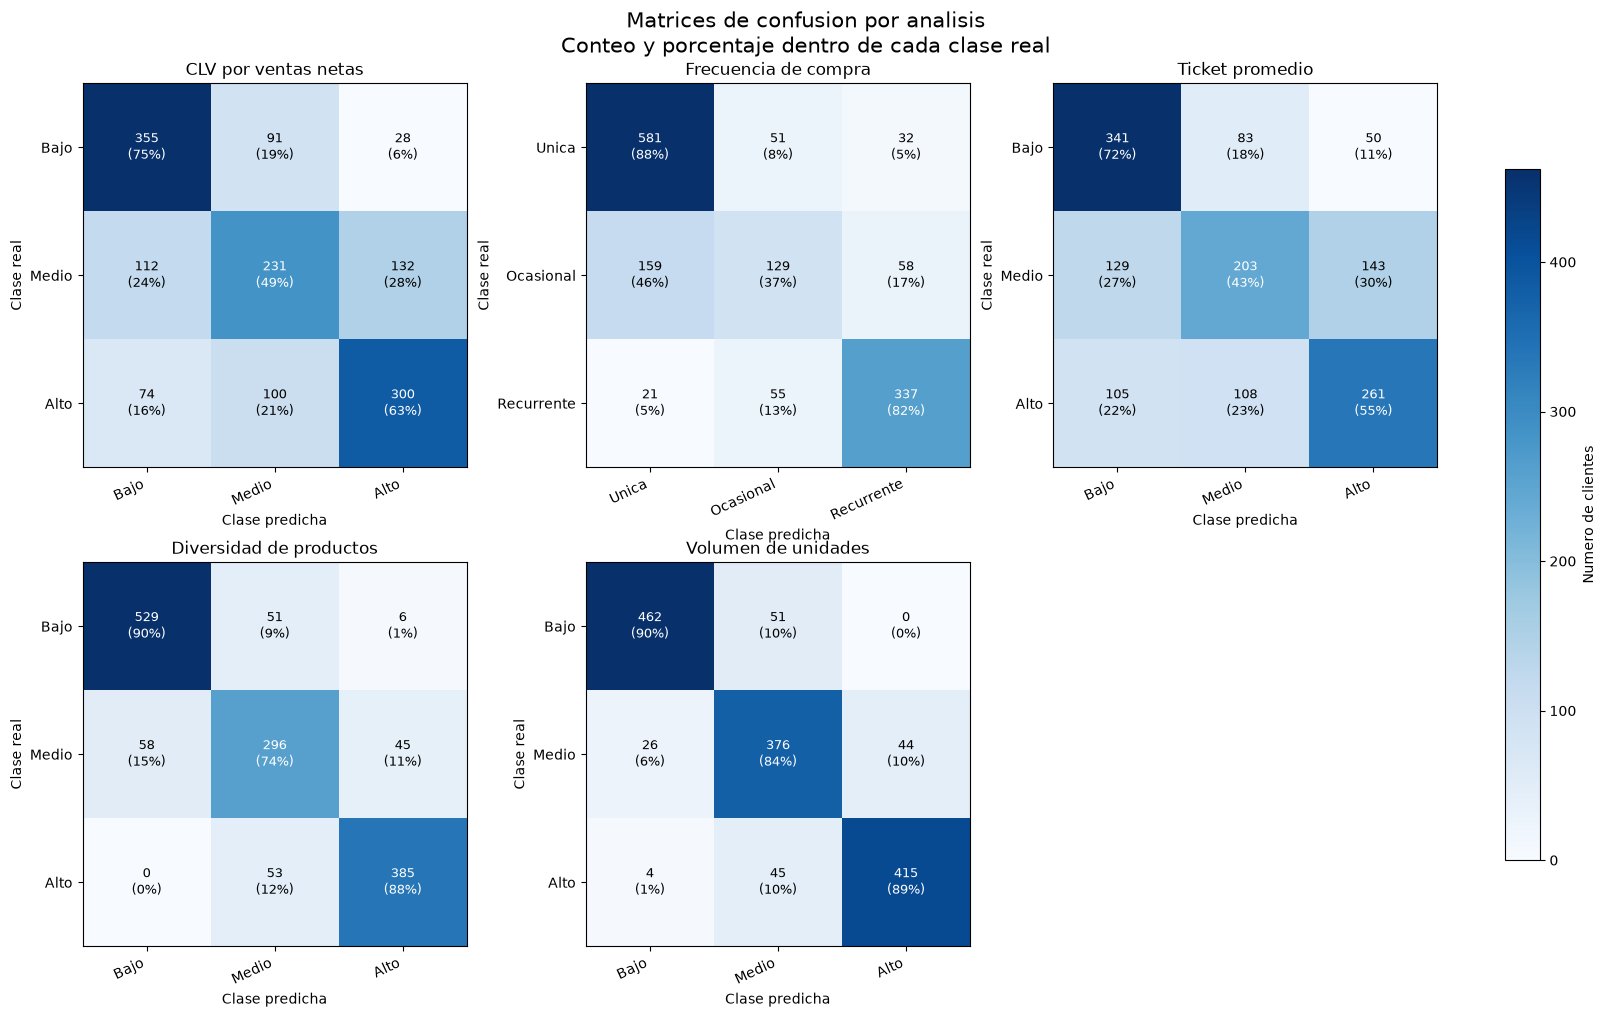

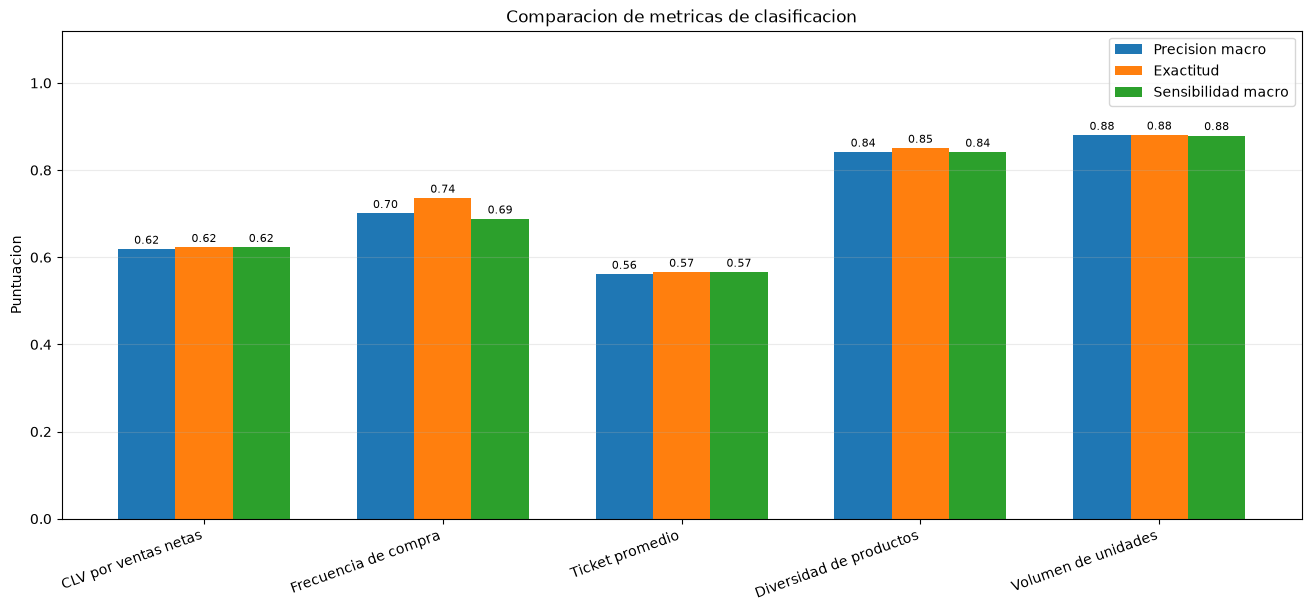

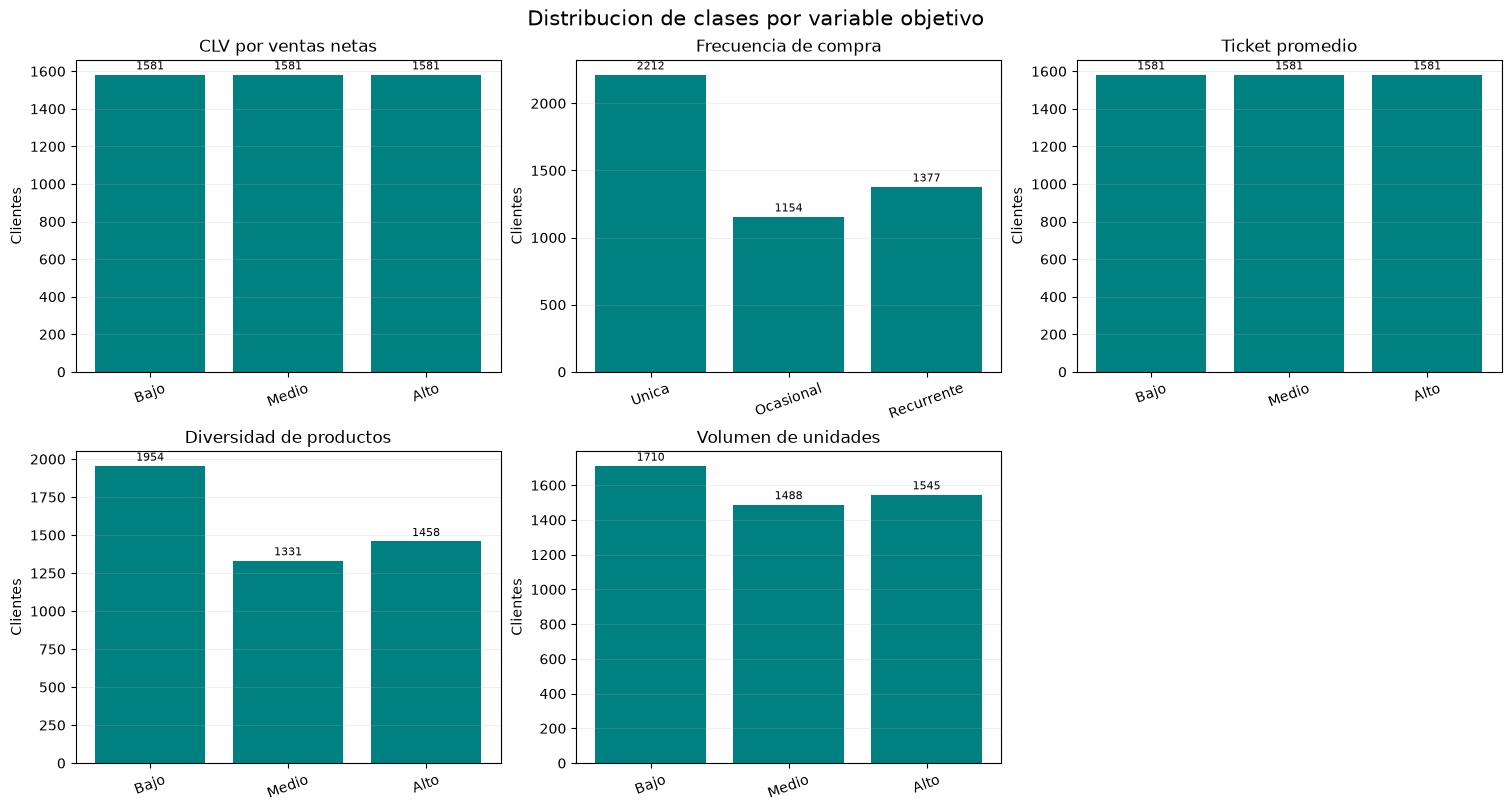

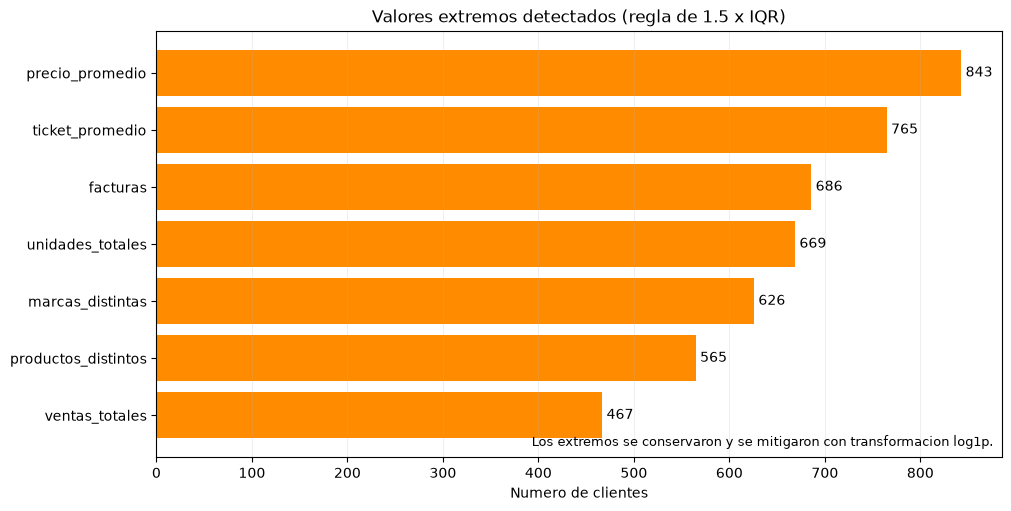

In [9]:
import matplotlib.pyplot as plt

# Matrices de confusion: filas = clase real; columnas = clase predicha.
fig, axes = plt.subplots(2, 3, figsize=(16, 10), constrained_layout=True)
for ax, (nombre, resultado) in zip(axes.flat, resultados.items()):
    matriz = resultado["matriz"]
    etiquetas = resultado["etiquetas"]
    imagen = ax.imshow(matriz, cmap="Blues")
    ax.set_title(nombre)
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")
    ax.set_xticks(range(len(etiquetas)), etiquetas, rotation=25, ha="right")
    ax.set_yticks(range(len(etiquetas)), etiquetas)
    totales_reales = matriz.sum(axis=1)
    for fila in range(matriz.shape[0]):
        for columna in range(matriz.shape[1]):
            porcentaje = matriz[fila, columna] / totales_reales[fila] if totales_reales[fila] else 0
            color = "white" if matriz[fila, columna] > matriz.max() / 2 else "black"
            ax.text(
                columna,
                fila,
                f"{matriz[fila, columna]}{chr(10)}({porcentaje:.0%})",
                ha="center",
                va="center",
                color=color,
                fontsize=9,
            )
axes.flat[-1].axis("off")
fig.colorbar(imagen, ax=axes.ravel().tolist()[:-1], shrink=0.8, label="Numero de clientes")
fig.suptitle("Matrices de confusion por analisis" + chr(10) + "Conteo y porcentaje dentro de cada clase real", fontsize=15)
plt.show()

# Comparacion directa de precision macro, exactitud y sensibilidad macro.
nombres = resumen.index.tolist()
metricas = ["Precision macro", "Exactitud", "Sensibilidad macro"]
posiciones = np.arange(len(nombres))
ancho = 0.24
fig, ax = plt.subplots(figsize=(13, 6), constrained_layout=True)
for indice, metrica in enumerate(metricas):
    valores = resumen[metrica].to_numpy()
    barras = ax.bar(posiciones + (indice - 1) * ancho, valores, ancho, label=metrica)
    ax.bar_label(barras, fmt="%.2f", padding=2, fontsize=8)
ax.set_title("Comparacion de metricas de clasificacion")
ax.set_ylabel("Puntuacion")
ax.set_ylim(0, 1.12)
ax.set_xticks(posiciones, nombres, rotation=20, ha="right")
ax.grid(axis="y", alpha=0.25)
ax.legend(loc="upper right")
plt.show()

# Balance de las categorias objetivo en los clientes analizados.
fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)
for ax, (nombre, especificacion) in zip(axes.flat, experimentos.items()):
    objetivo = especificacion["objetivo"]
    conteos = clientes[objetivo].value_counts(sort=False)
    barras = ax.bar(conteos.index.astype(str), conteos.values, color="teal")
    ax.bar_label(barras, fmt="%d", padding=2, fontsize=8)
    ax.set_title(nombre)
    ax.set_ylabel("Clientes")
    ax.tick_params(axis="x", labelrotation=20)
    ax.grid(axis="y", alpha=0.2)
axes.flat[-1].axis("off")
fig.suptitle("Distribucion de clases por variable objetivo", fontsize=15)
plt.show()

# Cantidad de valores extremos detectados por variable con la regla IQR.
outliers_grafica = pd.DataFrame(reporte_outliers).sort_values("Valores extremos")
fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
barras = ax.barh(outliers_grafica["Variable"], outliers_grafica["Valores extremos"], color="darkorange")
ax.bar_label(barras, fmt="%d", padding=3)
ax.set_title("Valores extremos detectados (regla de 1.5 x IQR)")
ax.set_xlabel("Numero de clientes")
ax.text(
    0.99,
    0.02,
    "Los extremos se conservaron y se mitigaron con transformacion log1p.",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=9,
)
ax.grid(axis="x", alpha=0.2)
plt.show()